# Site capacity: which forecast still works four weeks ahead?

**Two forecasters of a site's daily page views are level when they forecast next week. Booked four weeks ahead, which is the job here, one leaves the site short on 28% of days and the other on 13%. Spare capacity sized on next week's forecasts and used four weeks ahead aimed at 5% of days short and gave 24%. The test has to wait as long as the booking does. Before any of that, a generated weekly cycle with a known answer catches a one-day slip in the second forecaster, which the site's own data would have shown as a weaker forecaster and not as a bug.**

Capacity is booked ahead. Servers are reserved, a support roster is drawn up, a contract is signed, and all of it happens weeks before the traffic arrives. So a forecast for capacity always has a lead time, and the usual backtest, which forecasts the days right after the history ends, tests a different job. This notebook runs the same forecasters at five lead times, looks at where each one runs short, and then asks how much spare capacity to book on top.

*Data: daily page views of OTexts.com, a site of online textbooks, January 2018 to April 2022, from the R package fpp3 ([source and license](data/README.md#site-views)). To run this notebook yourself, see [Run an example yourself](../docs/examples.md#run-an-example-yourself).*

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from timegym import NaiveForecaster, Pipeline, Scenario, cases_from_series
from timegym.statistics import paired_t_interval

from example_data import load  # examples/example_data.py, next to this notebook

plt.rcParams.update({"figure.figsize": (12, 4), "figure.dpi": 110, "font.size": 11,
                     "figure.facecolor": "white", "axes.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": False, "legend.frameon": False, "axes.titlelocation": "left"})

## The job

OTexts publishes textbooks online, and its traffic follows the teaching year: it climbs when terms start and falls over the summer and at Christmas. Page views stand in for load here. They are the daily demand a capacity plan has to cover.

The plan: every Monday, book capacity for the week that starts four weeks later. Capacity for a day is the forecast for that day plus 20% headroom.

- A day is **short** when more views came than capacity was booked for.
- **Idle capacity** is the share of what was booked that went unused.

A good forecast gives few short days for little idle capacity. Either can be bought with the other by changing the headroom, so the tables below always show both.

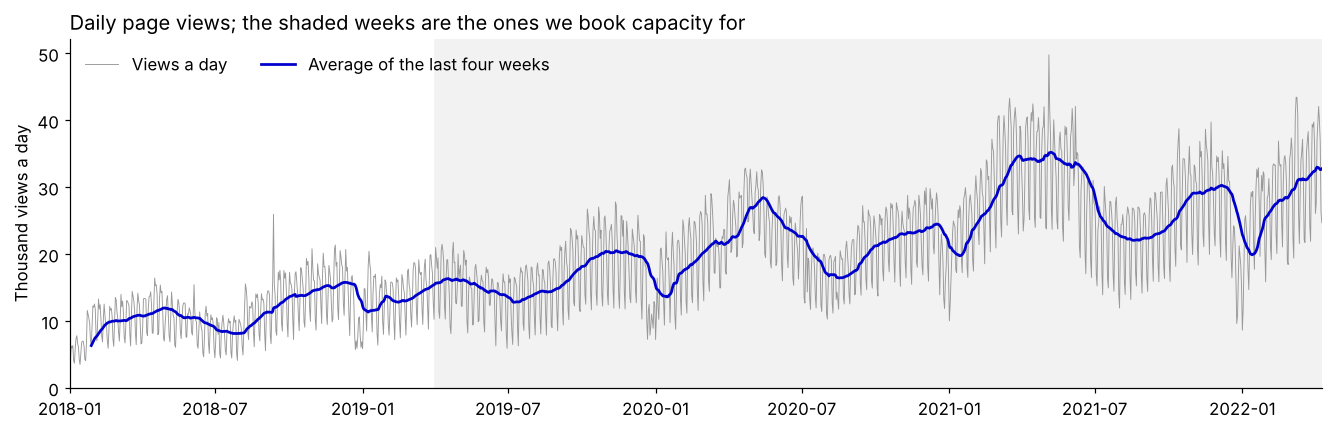

1,561 days, 1 January 2018 to 10 April 2022.
We book 158 weeks, 1 April 2019 to 10 April 2022: 1,106 days.
Monday to Friday averages 22,011 views a day, the weekend 13,992.
The busiest day, 5 May 2021, had 49,797 views.


In [2]:
views = load("site-views")["views"]

LEAD_WEEKS = 4      # a week of capacity is booked this many weeks before it starts
HEADROOM = 0.20     # capacity booked on top of the forecast
FIRST = 455         # the first week we book starts after this many days of data

starts = list(range(FIRST, len(views) - 6, 7))           # the first day of every week we book
actual = np.array([views.to_numpy(float)[day:day + 7] for day in starts])
booked_from, booked_to = views.index[starts[0]], views.index[starts[-1] + 6]

fig, ax = plt.subplots(figsize=(12, 3.8), layout="constrained")
ax.axvspan(booked_from, booked_to, color="0.95")
ax.plot(views.index, views / 1000, color="0.6", linewidth=0.6, label="Views a day")
ax.plot(views.index, views.rolling(28).mean() / 1000, color="#0000CC", linewidth=1.8,
        label="Average of the last four weeks")
ax.set(title="Daily page views; the shaded weeks are the ones we book capacity for",
       ylabel="Thousand views a day", ylim=(0, None), xlim=(views.index[0], views.index[-1]))
ax.legend(ncols=2, loc="upper left")
plt.show()

weekday = views.groupby(views.index.day_of_week).mean()
busiest = views.idxmax()
print(f"{len(views):,} days, {views.index[0].day} {views.index[0]:%B %Y} to "
      f"{views.index[-1].day} {views.index[-1]:%B %Y}.")
print(f"We book {len(starts)} weeks, {booked_from.day} {booked_from:%B %Y} to "
      f"{booked_to.day} {booked_to:%B %Y}: {actual.size:,} days.")
print(f"Monday to Friday averages {weekday[:5].mean():,.0f} views a day, the weekend {weekday[5:].mean():,.0f}.")
print(f"The busiest day, {busiest.day} {busiest:%B %Y}, had {views.max():,} views.")
assert len(views) == 1561 and len(starts) == 158 and booked_from.day_name() == "Monday"
assert views.index.freqstr == "D" and booked_to == views.index[-1]

The series grows from about 10,000 views a day to about 30,000, has a weekly cycle on top (weekends get two thirds of a weekday's views), and a yearly shape that repeats: two terms, a summer dip and a Christmas dip.

## Two forecasters

- **Recent weeks** forecasts each weekday at its average over the last four weeks. It follows the level and the weekly cycle and knows nothing about the time of year.
- **Last year** copies the same days a year back and scales them by how much the last four weeks grew on the same four weeks a year before. It knows the calendar.

Each is a few lines with `fit` and `predict`, which is all TimeGym asks of a forecaster. The obvious way to write "a year back" is 365 days.

In [3]:
class RecentWeeks:
    "Each weekday at its average over the last four weeks."

    def fit(self, history):
        values = np.asarray(history, dtype=float).ravel()
        self.week_ = values[-28:].reshape(4, 7).mean(axis=0)   # one number for each weekday
        return self

    def predict(self, dates):
        return np.resize(self.week_, len(dates))               # the week, repeated


class LastYear:
    "The same days a year back, scaled by the growth of the last four weeks on a year before."

    def __init__(self, back):
        self.back = back                                       # how many days back "a year" is

    def fit(self, history):
        values = np.asarray(history, dtype=float).ravel()
        self.values_ = values
        self.growth_ = values[-28:].sum() / values[-28 - self.back:-self.back].sum()
        return self

    def predict(self, dates):
        first = len(self.values_) - self.back
        return self.growth_ * self.values_[first:first + len(dates)]

## First, a series where the answer is known

Before either forecaster sees the site's data, it gets 20 generated series: a weekly cycle, noise, and nothing else. TimeGym generates them and keeps the true cycle, so a forecast is marked against the answer key and not against one noisy outcome. The mark is the typical distance between the forecast and the true cycle, counted in units of the noise. A flat line at the average is in the table as the mark to beat.

,Typical miss (noise = 1)
A flat line at the average,2.12
Recent weeks,0.52
"Last year, 365 days back",2.21


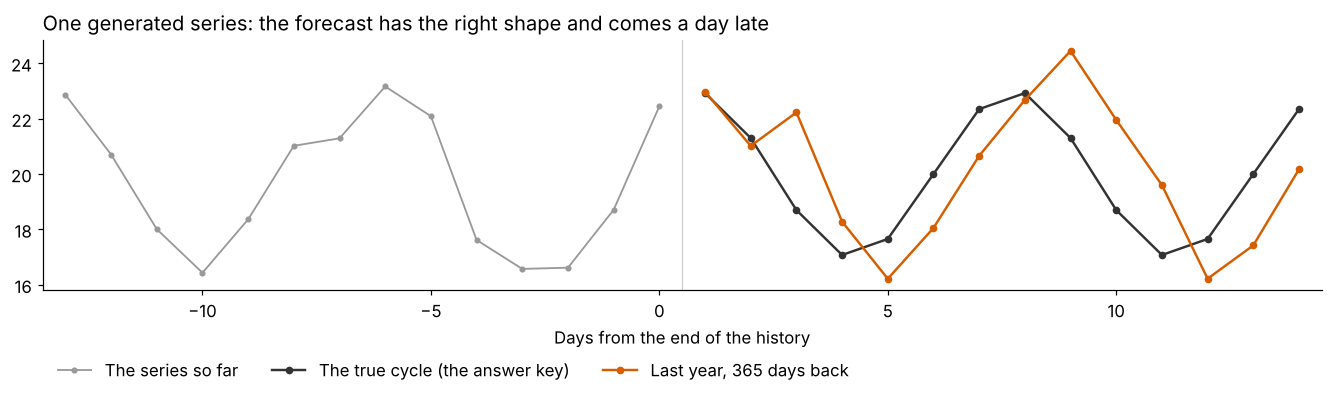

In [4]:
cycles = [Scenario("seasonal", context_length=800, horizon=35, seed=seed,
                   parameters={"mean": 20.0, "amplitude": 3.0, "period": 7.0, "sigma": 1.0})
          for seed in range(20)]


def typical_miss(model):
    "The typical distance between forecast and true cycle on the generated series, and the run."
    run = Pipeline(model).run(scenarios=cycles)
    squared = [entry.result.metrics["mean_reference_mse"] for entry in run.cases]
    return float(np.sqrt(np.mean(squared))), run


candidates = {"A flat line at the average": NaiveForecaster(strategy="mean"),
              "Recent weeks": RecentWeeks(), "Last year, 365 days back": LastYear(back=365)}
check = {name: typical_miss(model) for name, model in candidates.items()}
display(pd.Series({name: miss for name, (miss, run) in check.items()},
                  name="Typical miss (noise = 1)").round(2).to_frame())

entry = check["Last year, 365 days back"][1].cases[0]          # one generated series, as an example
history = entry.case.task.context["y"].to_numpy()[-14:]
day = np.arange(1, 15)
fig, ax = plt.subplots(figsize=(12, 3.4), layout="constrained")
ax.plot(day - 14, history, color="0.6", linewidth=1.2, marker="o", markersize=3, label="The series so far")
ax.plot(day, np.asarray(entry.case.reference.mean)[:14, 0], color="0.2", linewidth=1.6, marker="o",
        markersize=4, label="The true cycle (the answer key)")
ax.plot(day, entry.forecast.point[:14, 0], color="#D55E00", linewidth=1.6, marker="o", markersize=4,
        label="Last year, 365 days back")
ax.axvline(0.5, color="0.8", linewidth=0.8)
ax.set(title="One generated series: the forecast has the right shape and comes a day late",
       xlabel="Days from the end of the history", xlim=(-13.5, 14.5))
ax.legend(ncols=3, loc="lower left", bbox_to_anchor=(0, -0.42))
plt.show()

flat, recent_miss, slipped = (check[name][0] for name in check)
assert recent_miss < 0.6 and slipped > flat > 2, (flat, recent_miss, slipped)

Recent weeks gets 0.52: it averages four of each weekday, which halves the noise. Last year gets 2.21, worse than the flat line's 2.12, on a series that is nothing but the cycle it is meant to copy.

The picture shows why. The forecast has the right shape, one day late. A year of 365 days is 52 weeks and one day, so the copy of every Monday is taken from a Sunday. 364 days back is 52 whole weeks.

In [5]:
fixed, _ = typical_miss(LastYear(back=364))
print(f"Last year, 364 days back: a typical miss of {fixed:.2f}.")
assert abs(fixed - 1) < 0.1 and abs(slipped - 2.21) < 0.05 and abs(recent_miss - 0.52) < 0.05

Last year, 364 days back: a typical miss of 0.98.


It copies one day, noise and all, so about 1 is as good as this forecaster can get on such a series. From here on, **Last year** means 364 days back.

## The usual backtest, and the one for the job

`cases_from_series` cuts a case wherever we say and as long as we say. For a lead time of four weeks, a case ends four weeks before its week starts and asks for 35 days, and we keep the last seven. The same 158 weeks are booked at every lead time, from none (the usual backtest: forecast the week that starts tomorrow) to eight weeks.

The slipped version of Last year stays in as a third row, to see what the site's data would have said about it. "Off by a factor of" is how far a day's forecast is from its views as a ratio, so that 20,000 forecast for 10,000 and 10,000 forecast for 20,000 both count as 2.

,Off by a factor of,Days short (%),Idle (%)
Booked for next week,,,
Recent weeks,1.12,7.7,16.1
Last year,1.13,9.9,18.0
"Last year, 365 days back",1.24,23.3,20.7


,Off by a factor of,Days short (%),Idle (%)
Booked four weeks ahead,,,
Recent weeks,1.21,27.9,16.5
Last year,1.16,12.7,19.5
"Last year, 365 days back",1.26,23.9,21.9


Short days a week, Recent weeks less Last year:
  booked for next week    -0.16  (-0.38 to +0.06)
  booked four weeks ahead +1.06  (+0.63 to +1.50)


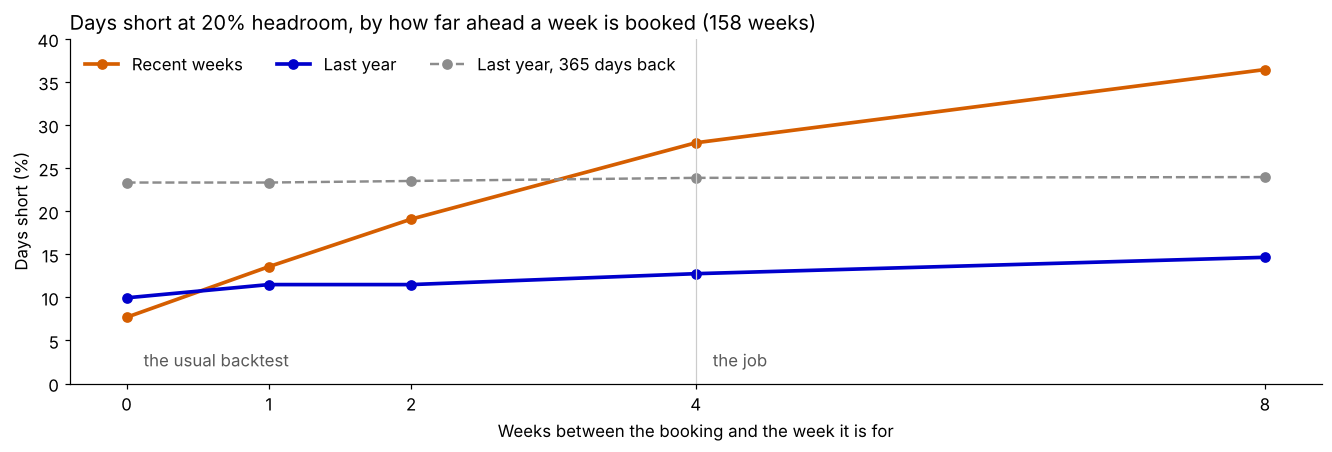

In [6]:
def book(model, lead_weeks=LEAD_WEEKS):
    "A forecast for each day of the 158 weeks, made this many weeks before each week starts."
    lead = 7 * lead_weeks
    cases = cases_from_series(views, [day - lead for day in starts], horizon=lead + 7, name="views")
    run = Pipeline(model).run(cases=cases)
    counts = run.report.summary["status_counts"]
    assert counts["FAIL"] == counts["ERROR"] == 0, counts
    assert [entry.case.manifest["context_length"] + lead for entry in run.cases] == starts
    return np.array([entry.forecast.point[lead:, 0] for entry in run.cases])


def short(forecast, headroom=HEADROOM):
    "For every day: did more views come than capacity was booked for?"
    return actual > (1 + headroom) * forecast


def idle(forecast, headroom=HEADROOM, weeks=slice(None)):
    "The share of booked capacity that went unused."
    booked = (1 + headroom) * forecast[weeks]
    return float(np.maximum(booked - actual[weeks], 0).sum() / booked.sum())


def scores(forecasts):
    return pd.DataFrame({name: {"Off by a factor of": np.exp(np.abs(np.log(forecast / actual)).mean()),
                                "Days short (%)": 100 * short(forecast).mean(),
                                "Idle (%)": 100 * idle(forecast)}
                         for name, forecast in forecasts.items()}).T


LEADS = (0, 1, 2, 4, 8)
forecasters = {"Recent weeks": RecentWeeks(), "Last year": LastYear(back=364),
               "Last year, 365 days back": LastYear(back=365)}
booked = {lead: {name: book(model, lead) for name, model in forecasters.items()} for lead in LEADS}

next_week, for_the_job = scores(booked[0]), scores(booked[LEAD_WEEKS])
decimals = {"Off by a factor of": 2, "Days short (%)": 1, "Idle (%)": 1}
display(next_week.round(decimals).rename_axis("Booked for next week"))
display(for_the_job.round(decimals).rename_axis("Booked four weeks ahead"))

print("Short days a week, Recent weeks less Last year:")
for label, lead in (("booked for next week", 0), ("booked four weeks ahead", LEAD_WEEKS)):
    more = short(booked[lead]["Recent weeks"]).sum(axis=1) - short(booked[lead]["Last year"]).sum(axis=1)
    gap = paired_t_interval(more)
    print(f"  {label:24s}{gap['mean']:+.2f}  ({gap['ci95'][0]:+.2f} to {gap['ci95'][1]:+.2f})")

fig, ax = plt.subplots(figsize=(12, 4), layout="constrained")
styles = {"Recent weeks": ("#D55E00", "-", 2.4), "Last year": ("#0000CC", "-", 2.4),
          "Last year, 365 days back": ("0.55", "--", 1.6)}
for name, (color, line, width) in styles.items():
    ax.plot(LEADS, [100 * short(booked[lead][name]).mean() for lead in LEADS], color=color, linestyle=line,
            linewidth=width, marker="o", markersize=6, label=name)
ax.axvline(LEAD_WEEKS, color="0.8", linewidth=0.8)
ax.annotate("the usual backtest", (0, 2), xytext=(0.12, 2), color="0.35")
ax.annotate("the job", (LEAD_WEEKS, 2), xytext=(LEAD_WEEKS + 0.12, 2), color="0.35")
ax.set(title=f"Days short at {HEADROOM:.0%} headroom, by how far ahead a week is booked ({len(starts)} weeks)",
       xlabel="Weeks between the booking and the week it is for", ylabel="Days short (%)",
       xticks=LEADS, ylim=(0, 40))
ax.legend(ncols=3, loc="upper left")
plt.show()

assert abs(next_week["Days short (%)"]["Recent weeks"] - next_week["Days short (%)"]["Last year"]) < 4
assert for_the_job["Days short (%)"]["Recent weeks"] > 2 * for_the_job["Days short (%)"]["Last year"]
assert gap["ci95"][0] > 0.4 and next_week["Off by a factor of"].idxmax() == "Last year, 365 days back"
assert np.allclose(for_the_job["Days short (%)"].to_numpy(), [27.9, 12.7, 23.9], atol=0.6)

Booked for next week, Recent weeks and Last year are level: off by a factor of 1.12 and 1.13, short on 8% and 10% of days, and the difference in short days is inside its interval. Booked four weeks ahead, Recent weeks is short on 28% of days and Last year on 13%, one more short day every week. The usual backtest would have let us pick either, and at the lead time of the job they are far apart. Recent weeks gets worse with every week of lead time. Last year hardly changes: its copy is a year old either way, and only its growth figure is four weeks staler.

The slipped Last year is off by a factor of about 1.25 at every lead time. In the usual backtest it is plainly the worst of the three, and the natural reading is that last year is a poor guide to this site, not that the code has a bug. With the bug fixed, it is the better of the two for the job.

## Where the short days are

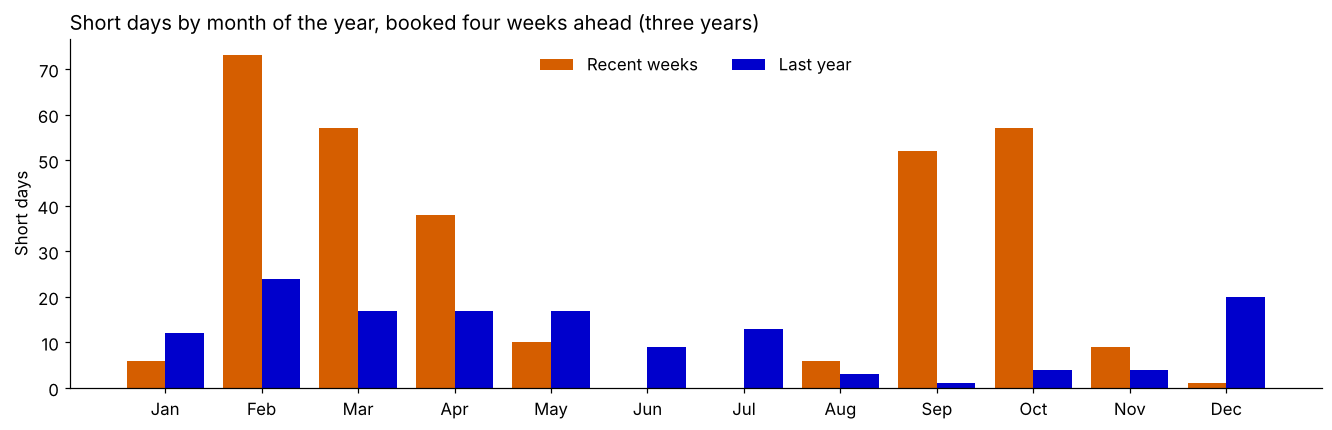

,Recent weeks,Last year,Days booked
"Short days, by year",,,
2019,61,30,280
2020,117,78,364
2021,92,29,364
2022,39,4,98


Recent weeks: 309 short days of 1,106. Of these, 239 are in February,
  March, September and October.
  Its forecast for February is 27% too low on average,
  and its forecast for July 27% too high.
Last year: 141 short days, 78 of them in 2020.


In [7]:
weeks = pd.DatetimeIndex([views.index[day] for day in starts])
job = booked[LEAD_WEEKS]
short_days = pd.DataFrame({name: short(job[name]).sum(axis=1) for name in ("Recent weeks", "Last year")},
                          index=weeks)
by_month = short_days.groupby(weeks.month).sum()

fig, ax = plt.subplots(figsize=(12, 3.8), layout="constrained")
month = np.arange(1, 13)
ax.bar(month - 0.2, by_month["Recent weeks"], width=0.4, color="#D55E00", label="Recent weeks")
ax.bar(month + 0.2, by_month["Last year"], width=0.4, color="#0000CC", label="Last year")
ax.set(title="Short days by month of the year, booked four weeks ahead (three years)",
       ylabel="Short days", xticks=month,
       xticklabels=["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
ax.legend(ncols=2, loc="upper center")
plt.show()

by_year = short_days.groupby(weeks.year).sum()
by_year["Days booked"] = 7 * short_days.groupby(weeks.year).size()
display(by_year.rename_axis("Short days, by year"))

term_start = np.isin(weeks.month, [2, 3, 9, 10])
miss = pd.Series(np.log(job["Recent weeks"] / actual).mean(axis=1), index=weeks)
miss = 100 * (np.exp(miss.groupby(weeks.month).mean()) - 1)
total = short_days.sum()
print(f"Recent weeks: {total['Recent weeks']} short days of {actual.size:,}. Of these, "
      f"{short_days.loc[term_start, 'Recent weeks'].sum()} are in February,")
print("  March, September and October.")
print(f"  Its forecast for February is {-miss[2]:.0f}% too low on average,")
print(f"  and its forecast for July {miss[7]:.0f}% too high.")
print(f"Last year: {total['Last year']} short days, {by_year.loc[2020, 'Last year']} of them in 2020.")
assert (by_year["Recent weeks"] > by_year["Last year"]).all()
assert (total["Recent weeks"], total["Last year"]) == (309, 141), total
assert short_days.loc[term_start, "Recent weeks"].sum() > 0.75 * total["Recent weeks"]

Recent weeks runs short when terms start: three quarters of its short days are in February, March, September and October. Booked four weeks ahead, its forecast for the first week of a term is an average of days five to eight weeks earlier, and those were holidays. It is 27% too low for February and 27% too high for July. No better average fixes that. The forecast needs the calendar.

Last year's short days are spread over the year, and more than half are in 2020, when traffic in the spring ran two thirds above the spring before and no earlier year said it would. Last year has fewer short days than Recent weeks in each of the four calendar years.

## Both together, and how much headroom

The two are wrong at different times, which is the best reason there is to average two forecasts. **Both** forecasts halfway between them (halfway as a ratio: between 10,000 and 40,000 that is 20,000).

And 20% headroom was a guess. The planner's question is how much headroom leaves the site short on at most 5% of days. We learn it from the weeks booked through 2020 and check it on the weeks after. The last row does what the usual backtest invites: it learns the headroom from forecasts of next week and books four weeks ahead with it.

,Headroom (%),Days short (%),Idle (%)
Checked from 2021 on,,,
Recent weeks,40.5,7.8,26.5
Last year,40.1,1.7,31.3
Both,35.1,1.7,25.6
"Recent weeks, sized on next week",22.8,23.6,17.8


Learned on 92 weeks, checked on 66 weeks (462 days) from 4 January 2021.
Short days in the check: 36, 8, 8, 109, in the order of the table.


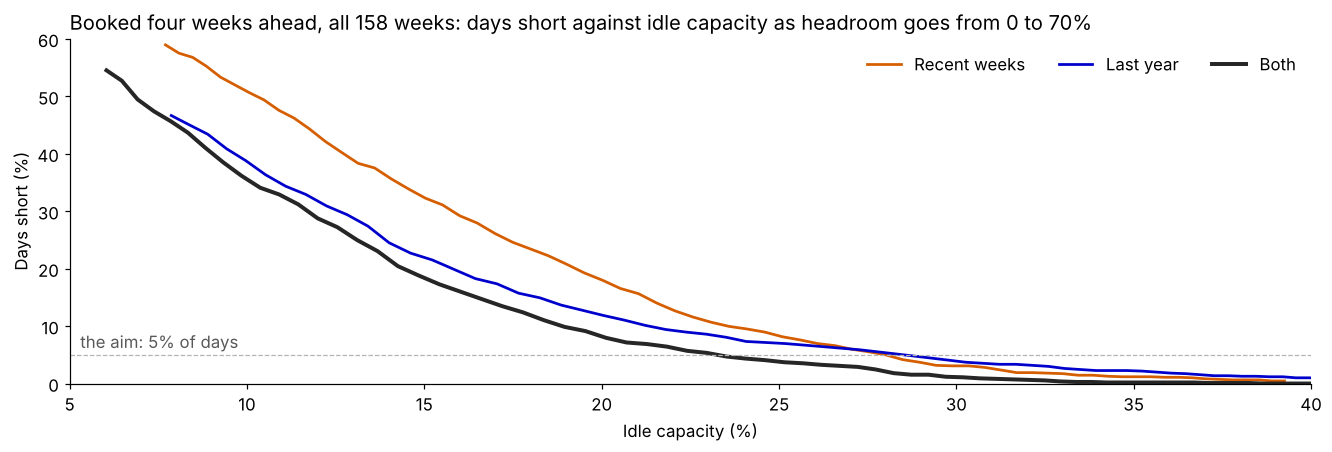

In [8]:
class Both:
    "Halfway, as a ratio, between Recent weeks and Last year."

    def fit(self, history):
        self.parts_ = [RecentWeeks().fit(history), LastYear(back=364).fit(history)]
        return self

    def predict(self, dates):
        return np.sqrt(self.parts_[0].predict(dates) * self.parts_[1].predict(dates))


TARGET = 0.05                                    # short on at most this share of days
learn = weeks.year <= 2020                       # learn the headroom here, check it on the rest
job["Both"] = book(Both())


def headroom_for(forecast):
    "The smallest headroom that would have kept the learning weeks to the target."
    return float(np.quantile((actual / forecast)[learn], 1 - TARGET)) - 1


def after(forecast, headroom):
    "What this headroom did on the weeks it was not learned from."
    late = short(forecast, headroom)[~learn]
    return {"Headroom (%)": 100 * headroom, "Days short (%)": 100 * late.mean(),
            "Idle (%)": 100 * idle(forecast, headroom, ~learn), "Short days": int(late.sum())}


plan = {name: after(job[name], headroom_for(job[name])) for name in ("Recent weeks", "Last year", "Both")}
plan["Recent weeks, sized on next week"] = after(job["Recent weeks"], headroom_for(booked[0]["Recent weeks"]))
plan = pd.DataFrame(plan).T
display(plan.drop(columns="Short days").round(1).rename_axis("Checked from 2021 on"))
print(f"Learned on {learn.sum()} weeks, checked on {(~learn).sum()} weeks ({7 * (~learn).sum()} days) "
      f"from {weeks[~learn][0].day} {weeks[~learn][0]:%B %Y}.")
print("Short days in the check: " + ", ".join(f"{days:.0f}" for days in plan["Short days"])
      + ", in the order of the table.")

fig, ax = plt.subplots(figsize=(12, 4), layout="constrained")
styles = {"Recent weeks": ("#D55E00", "-", 1.8), "Last year": ("#0000CC", "-", 1.8), "Both": ("0.15", "-", 2.6)}
for name, (color, line, width) in styles.items():
    steps = np.linspace(0, 0.7, 71)
    ax.plot([100 * idle(job[name], step) for step in steps], [100 * short(job[name], step).mean() for step in steps],
            color=color, linestyle=line, linewidth=width, label=name)
ax.axhline(100 * TARGET, color="0.7", linewidth=0.8, linestyle="--")
ax.annotate("the aim: 5% of days", (5.3, 100 * TARGET + 1.2), color="0.35")
ax.set(title="Booked four weeks ahead, all 158 weeks: days short against idle capacity as headroom goes "
             "from 0 to 70%",
       xlabel="Idle capacity (%)", ylabel="Days short (%)", ylim=(0, 60), xlim=(5, 40))
ax.legend(ncols=3, loc="upper right")
plt.show()

assert plan["Days short (%)"]["Recent weeks"] > 100 * TARGET > plan["Days short (%)"]["Both"]
assert plan["Idle (%)"]["Both"] < plan["Idle (%)"]["Last year"] - 3
assert plan["Days short (%)"]["Recent weeks, sized on next week"] > 4 * 100 * TARGET, plan
assert list(plan["Short days"]) == [36, 8, 8, 109] and np.allclose(plan["Headroom (%)"], [40.5, 40.1, 35.1, 22.8], atol=0.3)

Sized at the lead time it is used at, the headroom comes out near 40% for either forecaster alone and 35% for Both. On the 462 days from January 2021, Recent weeks was short on 36 days, 7.8% where the aim was 5%. Last year and Both were short on 8 days each, and Both got there with a quarter of its capacity idle where Last year had 31%. In the picture, which covers all 158 weeks, the black line is under the other two or level with them wherever the headroom is set.

The last row is the bill for the usual backtest. Sized on forecasts of next week, the headroom for Recent weeks is 23%. Used four weeks ahead, it left the site short on 109 of the 462 days, 24% where the aim was 5%.

The picture also qualifies what the tables above said. At 20% headroom Last year had less than half the short days of Recent weeks, and yet the two lines meet near the 5% mark. With enough headroom to cover the start of a term, over 40%, Recent weeks costs no more idle capacity than Last year. Last year's weak spot is a few very large misses in 2020, which no modest headroom covers. Each has a weakness the other lacks, and that is why the average of the two is under both.

## What TimeGym added

- **A test with an answer key.** `Scenario` generated 20 weekly cycles and kept the true cycle. The slipped forecaster scored worse than a flat line in under a second, before it saw any real data. On the site's data the same slip only looks like a weaker forecaster.
- **Cases cut for the lead time.** `cases_from_series` took the day each booking is made and a horizon that reaches the booked week. That gave the same 158 weeks at five lead times with no change to the forecasters.
- **Every forecast kept.** Short days, idle capacity, the count by month and the headroom were all worked out afterwards from the forecasts the runs kept. A new question about the plan did not need a new run.

## Change one thing

- Set `LEAD_WEEKS = 1` or `8`. Where do the short days of Recent weeks move to, and what happens to the headroom?
- Set `TARGET = 0.02`. Which forecaster does a stricter aim favor?
- Make `Both` forecast the higher of the two in place of the halfway point. It has fewer short days at the same headroom. Does it for the same idle capacity?
- `LastYear` measures growth on the last four weeks. Try eight or thirteen.

**What this doesn't show.** This is one site over three years, and one of the three is 2020. A site of textbooks has a stronger calendar than most. Where there is none, Last year has less to give, and the way to find out is the same test at your own lead time. Page views are not load: capacity is decided by the busiest hour, and a daily total hides it. Capacity that can be added in minutes does not need a forecast four weeks ahead. Short days come in runs, so the weeks are not independent and the intervals are somewhat too narrow. The headroom was learned on 92 weeks and checked on 66, which is one check and not a guarantee.

**Related:** [Weekly shop sales](store-sales.ipynb) weighs units short against leftover stock, the same two-sided cost for a shelf. [A traffic jump](traffic-jump.ipynb) is about the days a site's level jumps, which this plan would meet with its headroom. [Call center staffing](call-center.ipynb) is another job where the moment a forecast is made decides what it is worth. [Real-data forecasts](../tutorials/07_real_data_forecasts.ipynb) covers cutting cases from a series of your own, and [Custom model](../tutorials/02_custom_model.ipynb) covers writing a forecaster with `fit` and `predict`. More examples are on the [examples page](../docs/examples.md).